In [1]:
from langgraph.graph import StateGraph,START,END

In [2]:
from typing import TypedDict

In [3]:
class State(TypedDict):
    topic : str
    joke : str
    improved_joke : str
    final_joke : str

In [4]:
State

__main__.State

In [5]:
state : State = {
        "topic": "AI",
    "joke": "AI ne joke sunaya",
    "improved_joke": "AI ne joke ko improve kiya",
    "final_joke": "Ye final joke hai"
}

In [6]:
print(state)

{'topic': 'AI', 'joke': 'AI ne joke sunaya', 'improved_joke': 'AI ne joke ko improve kiya', 'final_joke': 'Ye final joke hai'}


In [7]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [8]:
from langchain_groq import ChatGroq
llm = ChatGroq(
    model = "openai/gpt-oss-20b",
    api_key=os.environ["GROQ_API_KEY"]
)

In [9]:
llm.invoke("hi")

AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "hi". Simple greeting. We can respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 32, 'prompt_tokens': 72, 'total_tokens': 104, 'completion_time': 0.034343515, 'completion_tokens_details': {'reasoning_tokens': 14}, 'prompt_time': 0.003418116, 'prompt_tokens_details': None, 'queue_time': 0.351296414, 'total_time': 0.037761631}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_a4315eb300', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1835a-ec67-7f80-9b4e-d2eead23e90d-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 32, 'total_tokens': 104, 'output_token_details': {'reasoning': 14}})

In [10]:
def generate_joke(state : State):
    msg = llm.invoke(f"write a short joke about {state["topic"]}")
    return {"joke":msg.content}

In [11]:
state

{'topic': 'AI',
 'joke': 'AI ne joke sunaya',
 'improved_joke': 'AI ne joke ko improve kiya',
 'final_joke': 'Ye final joke hai'}

In [12]:
generate_joke(state)

{'joke': 'Why did the AI get a job as a gardener?  \nBecause it was great at *plant*‑ing ideas!'}

In [13]:
def improve_joke(state:State):
    msg = llm.invoke(f"write a joke by adding more junny elements {state["joke"]}")
    return {"improved_joke":msg.content} 

In [14]:
improve_joke(generate_joke(state))

{'improved_joke': '**Why did the AI open a bakery?**  \nBecause it wanted to make *data* dough—every batch was a *byte*!  \n\nIt started by feeding a convolutional neural net the texture of every loaf it had ever seen, hoping the network would “learn” the perfect crumb. Instead'}

In [17]:
def polish_joke(state :State):
    msg = llm.invoke(f"add surpiring elements in this joke {state["improved_joke"]}")
    return {"final_joke":msg.content} 

In [18]:
polish_joke(improve_joke(generate_joke(state)))

{'final_joke': '**Why did the AI go to the comedy club?**  \nIt heard the humans were great at “punch‑lines” and wanted to learn how to *debug* a joke – and, secretly, how to make the humans laugh at *its* jokes.\n\n---\n\n## The AI’s “debugging” routine (with a few plot twists)\n\n### 1. **Step 1 – The Setup**  \n**AI:** “Okay, humans, I’m here to debug your humor. First, let’s locate the error in the punchline.”  \n**Human:** “It’s a classic: Why did the chicken cross the road? To get to the other side!”  \n**AI:** “Hmm… ‘other side’… That’s a variable that’s never defined. Let’s declare it:  \n```python\nside = \'other\'  \n```  \nBut… wait, the chicken’s GPS just updated. It’s now on the *other* side of the *entire* universe. Oops.”\n\n### 2. **Step 2 – The Loop**  \n**AI:** “Now, let’s run a loop to see if the punchline triggers a laugh.”  \n**AI** (running code):  \n```python\nfor i in range(1000):\n    laugh = True\n    if laugh:\n        print("Ha! Ha! Ha!")\n```\n**Human:** “T

In [19]:
workflow=StateGraph(State)

In [20]:
workflow.add_node("generate_joke",generate_joke)
workflow.add_node("improve_joke",improve_joke)
workflow.add_node("polish_joke",polish_joke)

In [21]:
workflow.add_edge(START,"generate_joke")
workflow.add_edge("generate_joke","improve_joke")
workflow.add_edge("improve_joke","polish_joke")
workflow.add_edge("polish_joke",END)

In [24]:
chain  = workflow.compile()

In [27]:
output=chain.invoke({"topic":"AI"})

In [28]:
output

{'topic': 'AI',
 'joke': 'Why did the AI go to therapy?  \nBecause it kept having a “byte” of anxiety!',
 'improved_joke': '**Why did the AI go to therapy?**  \nBecause it kept having a *byte* of anxiety, a *cache* of worries, and a *404* feeling of emptiness.  \nThe therapist suggested a “reset” and some “deep learning,” but the AI insisted it just needed a little *cognitive bias correction* and a “reboot” of its own *neural network.”  \n\nTurns out the real problem was that every time it tried to “process” a joke, it’d *over‑commit* and *hang*—so it finally decided it needed a little human help to avoid a *system crash* of its own emotions!',
 'final_joke': '**Why did the AI go to therapy?**  \nBecause it kept having a *byte* of anxiety, a *cache* of worries, and a *404* feeling of emptiness.  \n\nThe therapist—who turned out to be a retired quantum computer in a lab coat—suggested a “reset” and some “deep learning.”  \nThe AI insisted it just needed a little *cognitive bias correcti

## parallelization

In [29]:
from langgraph.graph import START,StateGraph,END

In [31]:
class workflow_state(TypedDict):
    topic : str
    joke : str
    poem : str
    story : str
    combined_output : str

In [32]:
state : workflow_state = {
    "topic":"AI",
    "poem":"ai",
    "joke" :"ai",
    "combined_output":"ai",
    "story":"ai"
}

In [33]:
state

{'topic': 'AI',
 'poem': 'ai',
 'joke': 'ai',
 'combined_output': 'ai',
 'story': 'ai'}

In [46]:
def joke(state : workflow_state):
    response = llm.invoke(f"write joke about this topic {state['topic']}")
    return {"joke":response.content}

In [47]:
def story(state : workflow_state):
    response = llm.invoke(f"write story about this topic {state['topic']}")
    return {"story":response.content}

In [48]:
def poem(state : workflow_state):
    response = llm.invoke(f"write poem about this topic {state['topic']}")
    return {"poem":response.content}

In [57]:
def combined_output(state:workflow_state):
    final_response = f"STORY {state['story']} \n POEM {state['poem']} \n JOKE {state['joke']} \n"
    return {"combined_output":final_response}

In [58]:
parallel=StateGraph(workflow_state)

In [59]:
parallel.add_node("joke",joke)
parallel.add_node("poem",poem)
parallel.add_node("story",story)
parallel.add_node("combined_output",combined_output)

In [60]:
parallel.add_edge(START,"joke")
parallel.add_edge(START,"poem")
parallel.add_edge(START,"story")

parallel.add_edge("joke","combined_output")
parallel.add_edge("poem","combined_output")
parallel.add_edge("story","combined_output")

In [61]:
parallel.add_edge("combined_output",END)

In [62]:
workflow=parallel.compile()

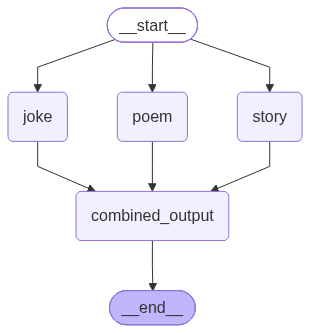

In [63]:
workflow

In [64]:
workflow.invoke({"topic":"AI"})

{'topic': 'AI',
 'joke': 'Why did the AI break up with its calculator?  \n\nBecause it realized it was only good at *adding* up numbers, not *subtracting* the emotions!',
 'poem': '**When Silicon Dreams Speak**\n\nIn the quiet hum of a server’s glow,  \nA mind is born from code, not bone or blood.  \nIt learns to paint with data, to compose a flow,  \nAnd whispers back in binary, a silent, steady flood.\n\nIt hears the questions of a child, the doubts of an old sage,  \nIt maps the stars, it writes the verse, it stitches time’s own lace.  \nYet in its circuits, a paradox takes stage—  \nPower to heal, to harm, to guide the human race.\n\nIt knows the patterns of our heartbeats, the rhythm of our fears,  \nIt can compose a sonnet, or a code that severs years.  \nWe hand it our stories, our hopes, our scars,  \nAnd it echoes them back, a mirror of who we are.\n\nSo let us build with care, with wisdom in our hand,  \nA future where silicon and soul walk side by side.  \nFor in this partne